# Track B: reinforcement learning

Train a policy on the model you identified in steps 1 to 3, then fly it on the drone in MATLAB.

1. Write a Gymnasium environment around your model (like `RocketLanderEnv` in TD 4). On the drone, the
   controller measures at each step ($T_s = 0.05$ s): `t`, `z`, `vz`, `az_prev`, `z_ref`, `u_prev`
   (`az_prev`, `u_prev`: acceleration and command of the previous step), and sends $u \in [-1, 1]$.
   `reset()` and `step()` return them in `info["m"]`.
2. Train a Stable-Baselines3 agent with an `MlpPolicy` on it, then export it with
   `export_for_matlab(agent, env)` (`export_policy.py`, do not edit): it writes `policy.mat` and `traj_model.mat`.
   Docs: [Stable-Baselines3](https://stable-baselines3.readthedocs.io/), and to follow the training,
   [TensorBoard with SB3](https://stable-baselines3.readthedocs.io/en/master/guide/tensorboard.html).
3. Write the same mission and observation in `mission()` and `observation()` of `rl_controller.m`, then run
   `EINT_RL_eval` in MATLAB. Complete the TODO in the matlab files to run the mission.

## 1. The environment (`drone_env.py`, built like `lib/rocket.py` of TD 4)

`drone_env.py`, next to this notebook (in `notebooks/`), contains the environment, organized like `RocketLanderEnv`: parameters at the top,
the physics in `dynamics`, the reward in `compute_reward`, then `DroneEnv`, then `run_episode`. Read it before running.

- **Model:** the RNN of notebook 02 (`../results/models/rnn_az.pt`), then az → vz → z by integration.
- **Measurements `info["m"]`:** `t, z, vz, az_prev, z_ref, u_prev` with the conventions of `EINT_RL_closed_loop.slx`
  (no ground, motors off at t = 0, `az_prev` and `u_prev` equal to 0 at the first step).
- **Observation (6 numbers):** height error, vz, az_prev / 10, u_prev, height error with the reference 0.5 s ahead, and the
  **integral of the error** (a memory, like the I of a PID: it removes a constant offset, the problem seen in the first try).
  The comment of `observation()` in `rl_controller.m` says that such a memory goes in a `persistent` variable: done.
- **Reward** (`compute_reward`): −(|height error| + 0.05 vz² + 0.5 (u − u_prev)² + 5 × depth below the support),
  −100 if the drone goes more than 2 m away. The term in u − u_prev smooths the command; the last one avoids hitting the platform
  (before 1 s) or the ground (after 5.5 s).
- **Training mode** (`train=True`): 70 % random missions, measurement noise, thrust changed by up to ±5 %.
  **Evaluation / export mode** (default): exact mission, no noise (`export_policy.py` requires an environment without noise).

As in TD 4, `check_env` first checks that the environment follows the Gymnasium API.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback
from drone_env import DroneEnv, run_episode, indicators, Z1, Z2

MODEL = '../results/models/rnn_az.pt'   # RNN trained in notebook 02
check_env(DroneEnv(MODEL))
print('check_env: OK')

check_env: OK


## 2. Training and export (the provided cell, completed)

Changes to the provided cell, and why:
- `env = DroneEnv(MODEL)`: our environment, **without noise**, used for the export as required;
- the agent is trained on `train_env` (random missions, noise, ±5 % thrust) to be robust to the real drone;
  `Monitor` records the training episodes (as in TD 4);
- `EvalCallback`: every 10 000 steps, flies the real mission on `env` and keeps the **best** agent
  (avoids ending on a worse version, which happened in the first try); we reload it before the export.
  If you stop the training before the end, the best agent so far is in `../results/checkpoints/best/`;
- `seed=0` for reproducible results;
- `net_arch=[64, 64]`: smaller networks than the default 256 × 256 (6 inputs and 1 output do not need more), 2-3 times faster.

To test a new reward quickly, first set `total_timesteps=30_000` (~10-15 min on a laptop), then `100_000` once it looks right.

`SAC("MlpPolicy", ...)` and `total_timesteps=100_000` are kept as provided. **Duration with 64 × 64: ~30-40 min on a laptop.**

In [2]:
from stable_baselines3 import SAC
from export_policy import export_for_matlab

env = DroneEnv(MODEL)                                         # exact mission, no noise: evaluation and export
train_env = Monitor(DroneEnv(MODEL, train=True, seed=0), '../results/checkpoints/sac/')   # results/checkpoints: ignored by Git
best = EvalCallback(Monitor(DroneEnv(MODEL)), eval_freq=10_000, n_eval_episodes=1,
                    best_model_save_path='../results/checkpoints/best/', deterministic=True, verbose=0)

agent = SAC("MlpPolicy", train_env, verbose=1, seed=0,
            policy_kwargs=dict(net_arch=[64, 64]))   # 2 hidden layers of 64 neurons instead of 256: ~2-3x faster
agent.learn(total_timesteps=100_000, callback=best)
agent = SAC.load('../results/checkpoints/best/best_model')     # the best agent seen during training

export_for_matlab(agent, env)   # env without noise: writes policy.mat and traj_model.mat

Using cpu device
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 14       |
|    ep_rew_mean     | -209     |
| time/              |          |
|    episodes        | 4        |
|    fps             | 4613     |
|    time_elapsed    | 0        |
|    total_timesteps | 56       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 15.5     |
|    ep_rew_mean     | -223     |
| time/              |          |
|    episodes        | 8        |
|    fps             | 290      |
|    time_elapsed    | 0        |
|    total_timesteps | 124      |
| train/             |          |
|    actor_loss      | -0.114   |
|    critic_loss     | 900      |
|    ent_coef        | 0.993    |
|    ent_coef_loss   | -0.011   |
|    learning_rate   | 0.0003   |
|    n_updates       | 23       |
---------------------------------
------------------------------

## 3. Check on our model before MATLAB

Flies the mission on our model (no noise) and prints the indicators. Targets before going to MATLAB:
error on the steps below 2 cm, overshoot below 5 cm.

RMSE (m)                                   +0.148
error on the 0.5 m step (m)                +0.006
overshoot above 0.5 m (m)                  +0.126
below the ground (m)                       +0.001
final error, last second (m)               +0.000


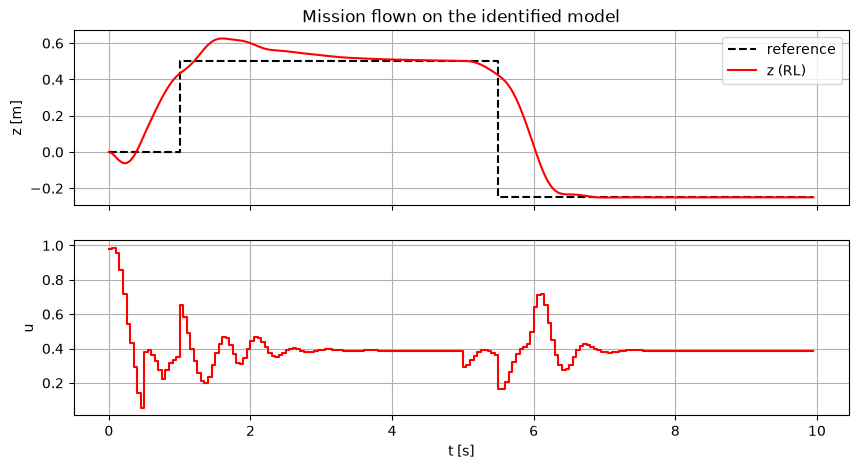

In [3]:
policy = lambda obs: agent.predict(obs, deterministic=True)[0]
L, _ = run_episode(env, policy)
for k, v in indicators(L).items():
    print(f'{k:42s} {v:+.3f}')

t, z, vz, u, zr = L.T
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].step(t, zr, 'k--', where='post', label='reference'); ax[0].plot(t, z, 'r', label='z (RL)')
ax[0].set_ylabel('z [m]'); ax[0].legend(); ax[0].grid()
ax[1].step(t, u, 'r', where='post'); ax[1].set_ylabel('u'); ax[1].set_xlabel('t [s]'); ax[1].grid()
ax[0].set_title('Mission flown on the identified model'); plt.show()

## 4. In MATLAB

`export_for_matlab` wrote `policy.mat` and `traj_model.mat` here, in `notebooks/` (do not commit them). `EINT_RL_eval.m` needs them
next to it, in the `rl_interface` folder of the provided files (next to `Matlab files`): the cell below copies them there.
Then in MATLAB: current folder = that `rl_interface` folder, run `EINT_RL_eval`. It must print `Check OK`, then fly the mission on
`UAV_model.slx` (`g_noise = 0.1`). `mission()` and `observation()` (with the integral in a `persistent` variable) are already
written at the end of `rl_controller.m` in that folder.

In [4]:
import shutil
from pathlib import Path
RL_DIR = Path(r'C:\Users\ezabl\Downloads\Student_folder\Student_folder\rl_interface')   # folder of EINT_RL_eval.m (change if needed)
for f in ('policy.mat', 'traj_model.mat'):
    shutil.copy(f, RL_DIR / f)
print('copied to', RL_DIR)

copied to C:\Users\ezabl\Downloads\Student_folder\Student_folder\rl_interface
